In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import time
import warnings
warnings.filterwarnings('ignore')

# Sklearn models
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR

# XGBoost and LightGBM
import xgboost as xgb
import lightgbm as lgb
import statsmodels.api as sm
from statsmodels.formula.api import ols


In [2]:
!nvidia-smi

Wed Nov 12 22:56:22 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 575.64.01              Driver Version: 576.88         CUDA Version: 12.9     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...    On  |   00000000:01:00.0 Off |                  N/A |
| N/A   82C    P0             18W /   60W |     330MiB /   4096MiB |     16%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using GPU:", torch.cuda.get_device_name(0))
    print("Memory Allocated:", torch.cuda.memory_allocated(0)/(1024**2), "MB")
    print("Memory Cached:", torch.cuda.memory_reserved(0)/(1024**2), "MB")
    print("Max Memory Allocated:", torch.cuda.max_memory_allocated(0)/(1024**2), "MB")
    print("GPU Memory: ", (torch.cuda.get_device_properties(0).total_memory/(1024**2)).__round__(4), "MB")
else:
    device = torch.device("cpu")
    print("Using CPU")

Using GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Memory Allocated: 0.0 MB
Memory Cached: 0.0 MB
Max Memory Allocated: 0.0 MB
GPU Memory:  4095.5 MB


In [4]:
# Load data
df = pd.read_parquet('clean.parquet')

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nDataset sample:")
print(df.sample())
print("\nTarget (trip_duration) statistics:")
if 'trip_duration' in df.columns:
    print(df['trip_duration'].describe())
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (619871, 8)

Columns: ['fare_amount', 'extra', 'mta_tax', 'tolls_amount', 'payment_type', 'dropoff_borough', 'pickup_borough', 'trip_duration']

Data types:
fare_amount        double[pyarrow]
extra              double[pyarrow]
mta_tax            double[pyarrow]
tolls_amount       double[pyarrow]
payment_type               float64
dropoff_borough           category
pickup_borough            category
trip_duration              float64
dtype: object

Dataset sample:
        fare_amount  extra  mta_tax  tolls_amount  payment_type  \
145758         14.5    0.0      0.5           0.0           1.0   

       dropoff_borough pickup_borough  trip_duration  
145758       Manhattan      Manhattan      19.566667  

Target (trip_duration) statistics:
        fare_amount  extra  mta_tax  tolls_amount  payment_type  \
145758         14.5    0.0      0.5           0.0           1.0   

       dropoff_borough pickup_borough  trip_duration  
145758       Manhattan      Manhattan      19.

In [5]:
df.dropoff_borough

11           Queens
12         Brooklyn
13           Queens
14           Queens
15           Queens
            ...    
623502     Brooklyn
623503     Brooklyn
623504        Bronx
623505    Manhattan
623506    Manhattan
Name: dropoff_borough, Length: 619871, dtype: category
Categories (7, object): ['Bronx', 'Brooklyn', 'EWR', 'Manhattan', 'Queens', 'Staten Island', 'Unknown']

In [6]:
# Prepare data for training
# Separate features and target
y = df['trip_duration'].values
X = df.drop('trip_duration', axis=1)

# Identify categorical columns
categorical_cols = ['payment_type', 'dropoff_borough', 'pickup_borough']

# Split data first (80/20 train/test) - maintain same random_state for consistent splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Original data split completed")
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Categorical columns: {categorical_cols}")


Original data split completed
Train shape: (495896, 7), Test shape: (123975, 7)
Categorical columns: ['payment_type', 'dropoff_borough', 'pickup_borough']


In [7]:
# Helper function to evaluate models
def evaluate_model(y_true, y_pred, model_name):
    """Calculate and print regression metrics with visualization"""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    print(f"\n{'='*60}")
    print(f"{model_name} - Test Set Performance")
    print(f"{'='*60}")
    print(f"RMSE:  {rmse:.4f}")
    print(f"MAE:   {mae:.4f}")
    print(f"R² Score: {r2:.4f}")
    print(f"{'='*60}")
    
    abs_errors = np.abs(y_true - y_pred)
    # Store absolute errors for downstream statistical testing
    model_error_distributions[model_name] = abs_errors
    # Create Real vs Predicted scatter plot
    fig, ax = plt.subplots(figsize=(8, 8))
    
    # Scatter plot
    ax.scatter(y_true, y_pred, alpha=0.5, s=50, edgecolors='k', linewidths=0.5)
    
    # Perfect prediction line (y=x)
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
    
    # Labels and title
    ax.set_xlabel('Actual Trip Duration (minutes)', fontsize=12)
    ax.set_ylabel('Predicted Trip Duration (minutes)', fontsize=12)
    ax.set_title(f'{model_name}\nActual vs Predicted Trip Duration', fontsize=14, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    # Add metrics as text box
    textstr = f'RMSE: {rmse:.4f}\nMAE: {mae:.4f}\nR²: {r2:.4f}'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.show()
    
    return {'model': model_name, 'rmse': rmse, 'mae': mae, 'r2': r2}

# Store results for comparison
results = []
model_error_distributions = {}

## 1. Decision Tree Regressor (sklearn)

Training Decision Tree Regressor...
Decision Tree data shape: (495896, 20)
Training time: 0.97 seconds

Decision Tree - Test Set Performance
RMSE:  25.8113
MAE:   3.7076
R² Score: 0.2640
Training time: 0.97 seconds

Decision Tree - Test Set Performance
RMSE:  25.8113
MAE:   3.7076
R² Score: 0.2640


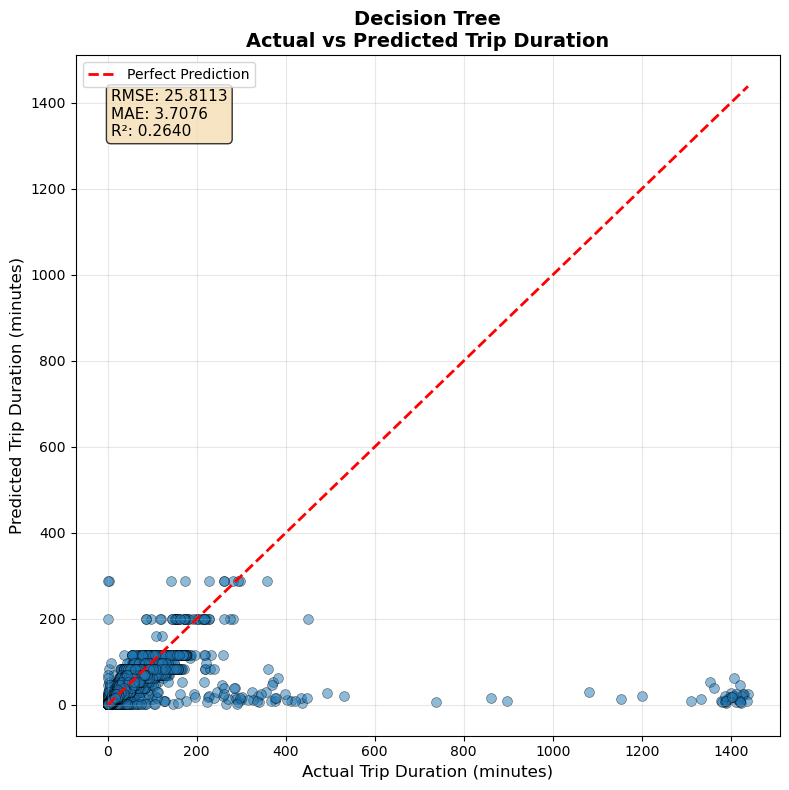

In [20]:
print("Training Decision Tree Regressor...")
start_time = time.time()

# Prepare data for Decision Tree: No scaling, convert categories to dummies
X_train_dt = X_train.copy()
X_test_dt = X_test.copy()

# Convert categorical columns to category dtype then create dummies
for col in categorical_cols:
    X_train_dt[col] = X_train_dt[col].astype('category')
    X_test_dt[col] = X_test_dt[col].astype('category')

X_train_dt = pd.get_dummies(X_train_dt, columns=categorical_cols, drop_first=True)
X_test_dt = pd.get_dummies(X_test_dt, columns=categorical_cols, drop_first=True)

# Ensure both train and test have the same columns
X_train_dt, X_test_dt = X_train_dt.align(X_test_dt, join='left', axis=1, fill_value=0)

print(f"Decision Tree data shape: {X_train_dt.shape}")

# Decision Tree with reasonable hyperparameters
dt_model = DecisionTreeRegressor(
    max_depth=5,  
    min_samples_split=3,
    min_samples_leaf=3,
    random_state=42
)

dt_model.fit(X_train_dt, y_train)
y_pred_dt = dt_model.predict(X_test_dt)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_dt, "Decision Tree"))


In [21]:
del X_train_dt, X_test_dt, dt_model, y_pred_dt
import gc
gc.collect()

4642

## 2. K-Nearest Neighbors (sklearn)

Training K-Nearest Neighbors Regressor...
KNN data shape: (495896, 20)
KNN data shape: (495896, 20)
Training time: 141.33 seconds

K-Nearest Neighbors - Test Set Performance
RMSE:  26.2424
MAE:   3.6161
R² Score: 0.2393
Training time: 141.33 seconds

K-Nearest Neighbors - Test Set Performance
RMSE:  26.2424
MAE:   3.6161
R² Score: 0.2393


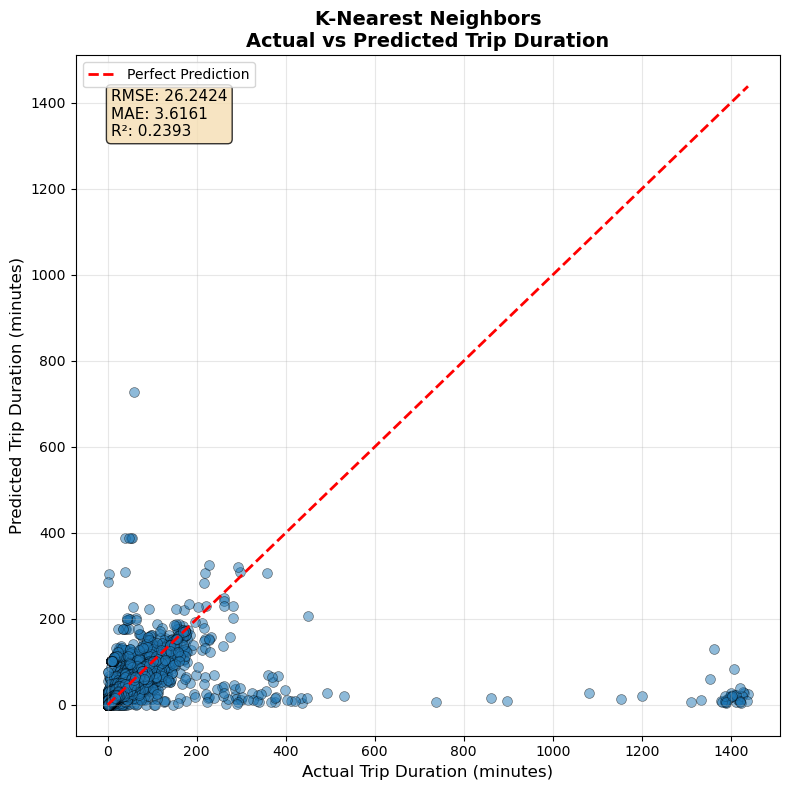

In [22]:
print("Training K-Nearest Neighbors Regressor...")
start_time = time.time()

# Prepare data for KNN: MinMax scaling, convert categories to dummies
X_train_knn = X_train.copy()
X_test_knn = X_test.copy()

# Convert categorical columns to category dtype then create dummies
for col in categorical_cols:
    X_train_knn[col] = X_train_knn[col].astype('category')
    X_test_knn[col] = X_test_knn[col].astype('category')

X_train_knn = pd.get_dummies(X_train_knn, columns=categorical_cols, drop_first=True)
X_test_knn = pd.get_dummies(X_test_knn, columns=categorical_cols, drop_first=True)

# Ensure both train and test have the same columns
X_train_knn, X_test_knn = X_train_knn.align(X_test_knn, join='left', axis=1, fill_value=0)

# Apply MinMax scaling
scaler_knn = MinMaxScaler()
X_train_knn = scaler_knn.fit_transform(X_train_knn)
X_test_knn = scaler_knn.transform(X_test_knn)

print(f"KNN data shape: {X_train_knn.shape}")

# KNN with appropriate parameters
knn_model = KNeighborsRegressor(
    n_neighbors=3,  
    weights='distance',
    n_jobs=-1
)

knn_model.fit(X_train_knn, y_train)
y_pred_knn = knn_model.predict(X_test_knn)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_knn, "K-Nearest Neighbors"))


In [23]:
del X_train_knn, X_test_knn, scaler_knn, knn_model, y_pred_knn
import gc
gc.collect()

3909

## 3. Random Forest Regressor (sklearn)

Training Random Forest Regressor...
Random Forest data shape: (495896, 20)
Training time: 12.30 seconds

Random Forest - Test Set Performance
RMSE:  25.8291
MAE:   4.1921
R² Score: 0.2630
Training time: 12.30 seconds

Random Forest - Test Set Performance
RMSE:  25.8291
MAE:   4.1921
R² Score: 0.2630


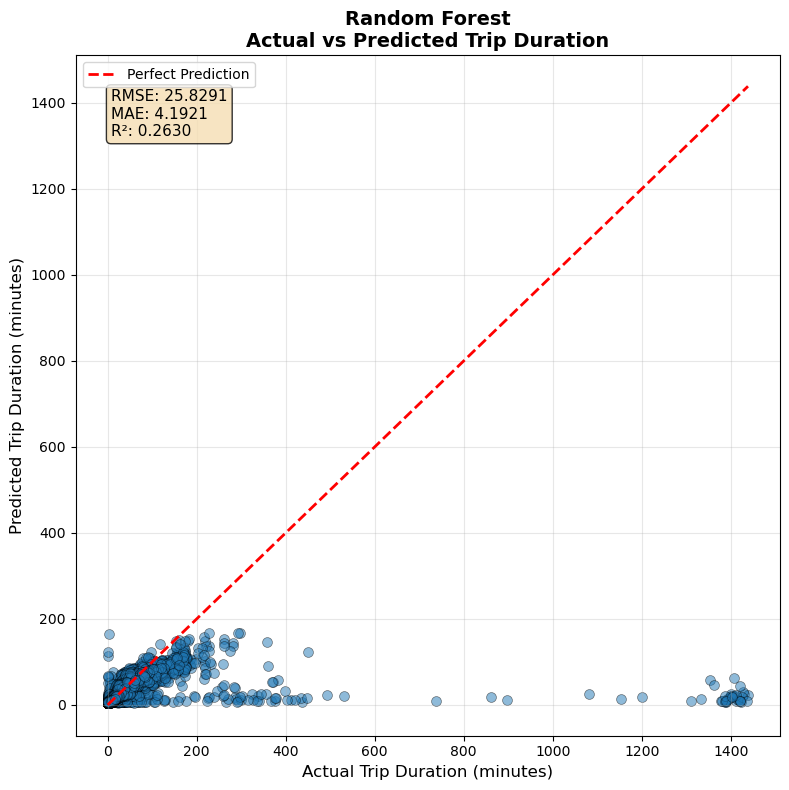

In [24]:
print("Training Random Forest Regressor...")
start_time = time.time()

# Prepare data for Random Forest: No scaling, convert categories to dummies
X_train_rf = X_train.copy()
X_test_rf = X_test.copy()

# Convert categorical columns to category dtype then create dummies
for col in categorical_cols:
    X_train_rf[col] = X_train_rf[col].astype('category')
    X_test_rf[col] = X_test_rf[col].astype('category')

X_train_rf = pd.get_dummies(X_train_rf, columns=categorical_cols, drop_first=True)
X_test_rf = pd.get_dummies(X_test_rf, columns=categorical_cols, drop_first=True)

# Ensure both train and test have the same columns
X_train_rf, X_test_rf = X_train_rf.align(X_test_rf, join='left', axis=1, fill_value=0)

print(f"Random Forest data shape: {X_train_rf.shape}")

# Random Forest with balanced hyperparameters
rf_model = RandomForestRegressor(
    n_estimators=100,  # Number of trees
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',  # Use sqrt(n_features) at each split
    n_jobs=-1,  # Use all CPU cores
    random_state=42
)

rf_model.fit(X_train_rf, y_train)
y_pred_rf = rf_model.predict(X_test_rf)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_rf, "Random Forest"))


In [25]:
del X_train_rf, X_test_rf, rf_model, y_pred_rf
import gc
gc.collect()

4002

## 4. Neural Network (PyTorch - CPU)
By design deep neural networks expect normalized (normal distributed) input data. Therefore, we will apply standardization instead of min-max scaling to our features in this model.

In [26]:

# Define Neural Network with GPU-optimized architecture
class RegressionNN(nn.Module):
    def __init__(self, input_dim):
        super(RegressionNN, self).__init__()
        
        # Attention mechanism (keep simple for efficiency)
        self.attention = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.Tanh(),
            nn.Linear(128, input_dim),
            nn.Softmax(dim=1)
        )
        
        self.network = nn.Sequential(
            nn.Linear(input_dim, 352),
            nn.BatchNorm1d(352),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(352, 288),
            nn.BatchNorm1d(288),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            
            nn.Linear(288, 224),
            nn.BatchNorm1d(224),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            
            nn.Linear(224, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        attention_weights = self.attention(x)
        x_attended = x * attention_weights
        
        # Forward through main network
        return self.network(x_attended)

In [27]:
from sklearn.preprocessing import PowerTransformer

# Prepare data for Neural Network: Mixed scaling approach (scale BEFORE dummies)
X_train_nn = X_train.copy()
X_test_nn = X_test.copy()

# Identify numeric columns (before creating dummies)
numeric_cols_all = [col for col in X_train_nn.columns if col not in categorical_cols]

# Separate columns for different scaling approaches
std_scaler_cols = ['mta_tax', 'extra']
power_transform_cols = [col for col in numeric_cols_all if col not in std_scaler_cols]

# Apply StandardScaler to mta_tax and extra
scaler_std = StandardScaler()
X_train_nn[std_scaler_cols] = scaler_std.fit_transform(X_train_nn[std_scaler_cols])
X_test_nn[std_scaler_cols] = scaler_std.transform(X_test_nn[std_scaler_cols])

# Apply PowerTransformer to other numeric columns
scaler_power = PowerTransformer()
X_train_nn[power_transform_cols] = scaler_power.fit_transform(X_train_nn[power_transform_cols])
X_test_nn[power_transform_cols] = scaler_power.transform(X_test_nn[power_transform_cols])

print(f"StandardScaler applied to: {std_scaler_cols}")
print(f"PowerTransformer applied to: {power_transform_cols}")

# NOW convert categorical columns to dummies (after scaling numeric features)
for col in categorical_cols:
    X_train_nn[col] = X_train_nn[col].astype('category')
    X_test_nn[col] = X_test_nn[col].astype('category')

X_train_nn = pd.get_dummies(X_train_nn, columns=categorical_cols, drop_first=True)
X_test_nn = pd.get_dummies(X_test_nn, columns=categorical_cols, drop_first=True)

# Ensure both train and test have the same columns
X_train_nn, X_test_nn = X_train_nn.align(X_test_nn, join='left', axis=1, fill_value=0)

# Store column names
nn_column_names = X_train_nn.columns.tolist()

# Ensure all columns are numeric (convert any remaining object columns to float)
X_train_nn = X_train_nn.astype('float64')
X_test_nn = X_test_nn.astype('float64')

# Convert to numpy arrays
X_train_nn = X_train_nn.values
X_test_nn = X_test_nn.values

print(f"Neural Network data shape: {X_train_nn.shape}")
print(f"Data type: {X_train_nn.dtype}")
print(f"Dummy variables remain in [0,1] range (not transformed)")

# Check if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

X_train_tensor = torch.FloatTensor(X_train_nn)
y_train_tensor = torch.FloatTensor(y_train).unsqueeze(1)
X_test_tensor = torch.FloatTensor(X_test_nn)
y_test_tensor = torch.FloatTensor(y_test).unsqueeze(1)


input_dim = X_train_nn.shape[1]
print(f"Neural Network input dimension: {input_dim}")


StandardScaler applied to: ['mta_tax', 'extra']
PowerTransformer applied to: ['fare_amount', 'tolls_amount']
Neural Network data shape: (495896, 20)
Data type: float64
Dummy variables remain in [0,1] range (not transformed)
Using device: cuda
Neural Network input dimension: 20
Neural Network data shape: (495896, 20)
Data type: float64
Dummy variables remain in [0,1] range (not transformed)
Using device: cuda
Neural Network input dimension: 20


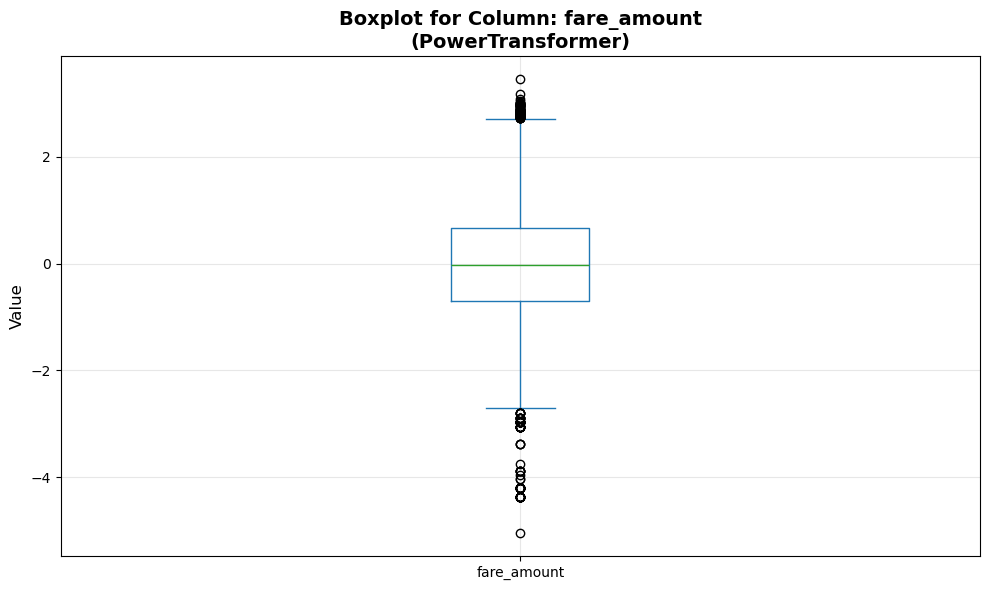

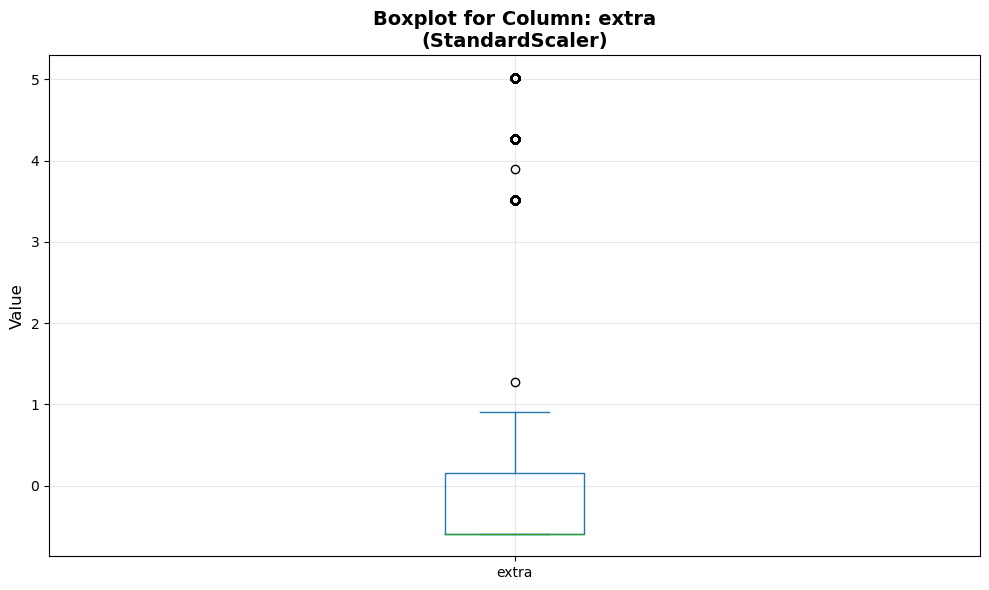

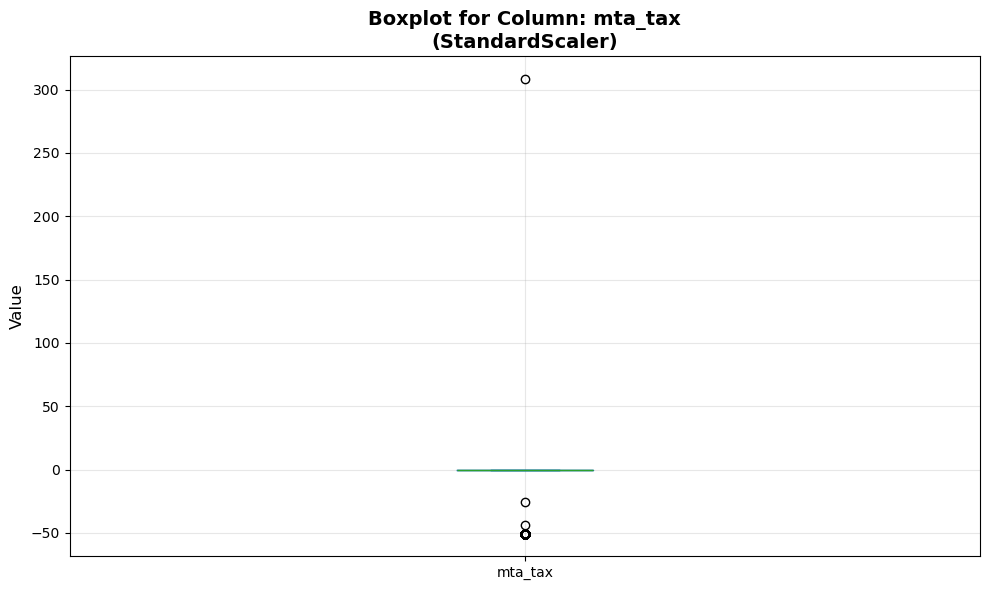

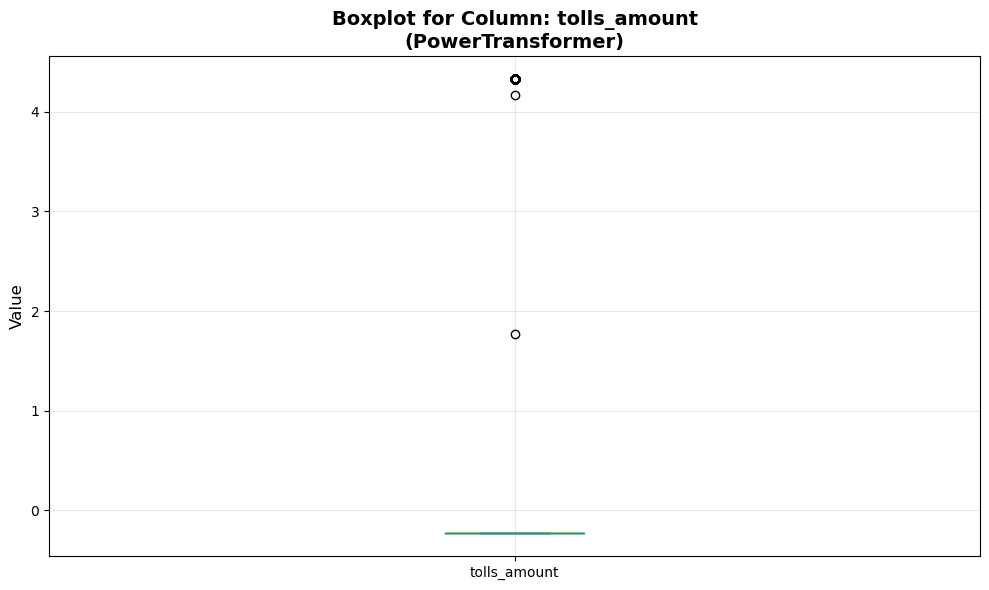

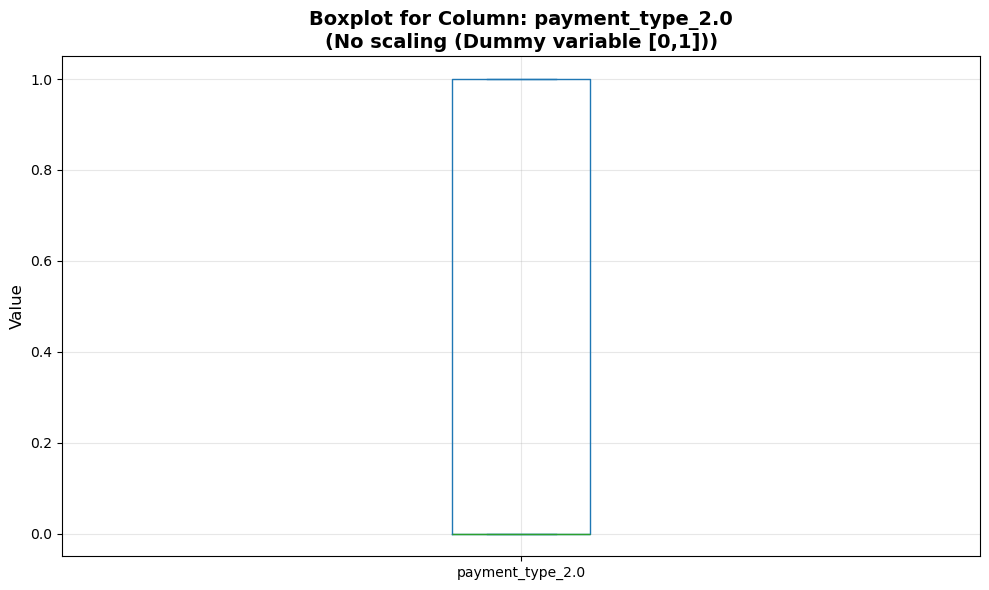

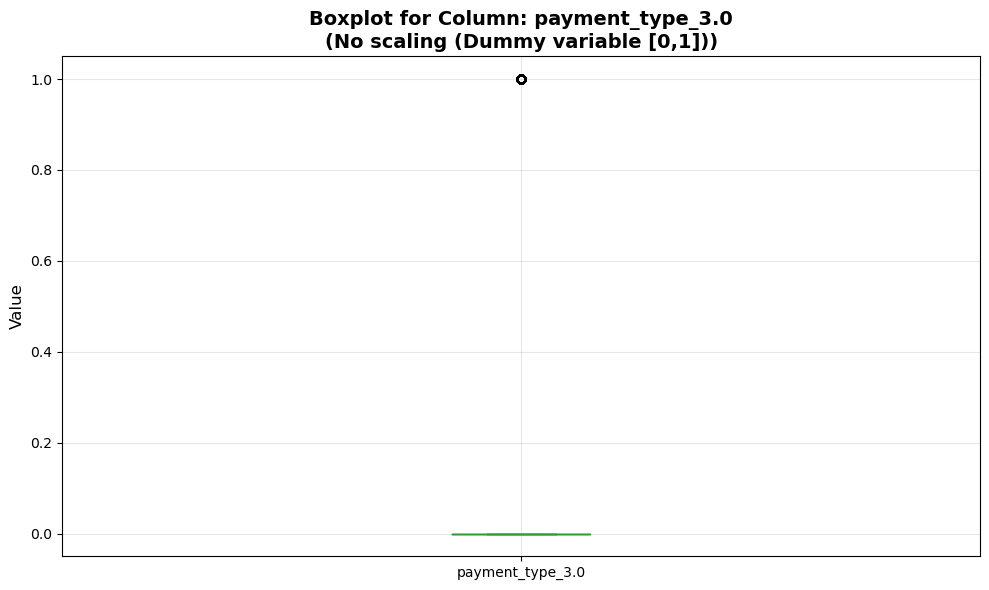

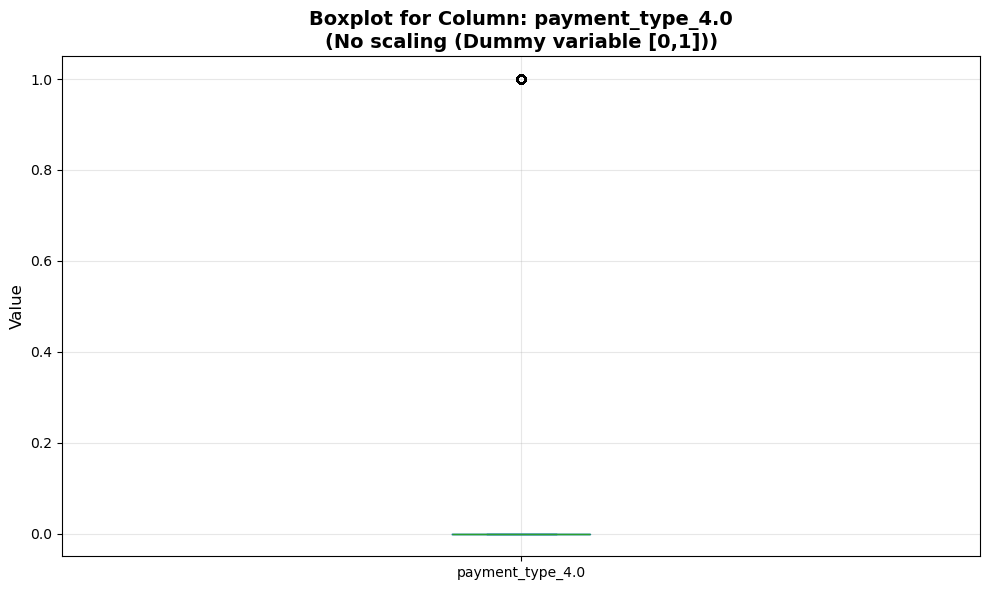

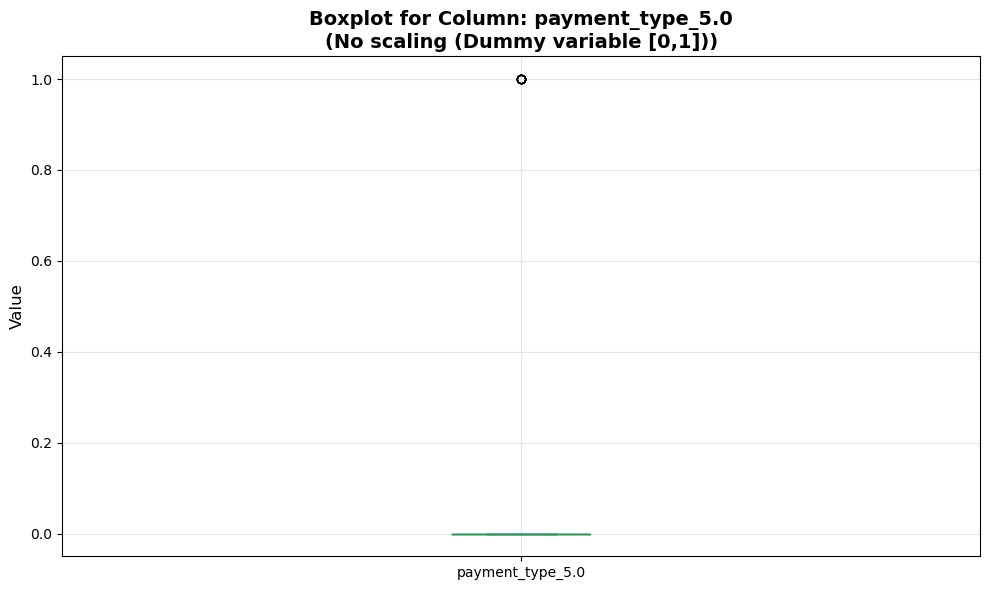

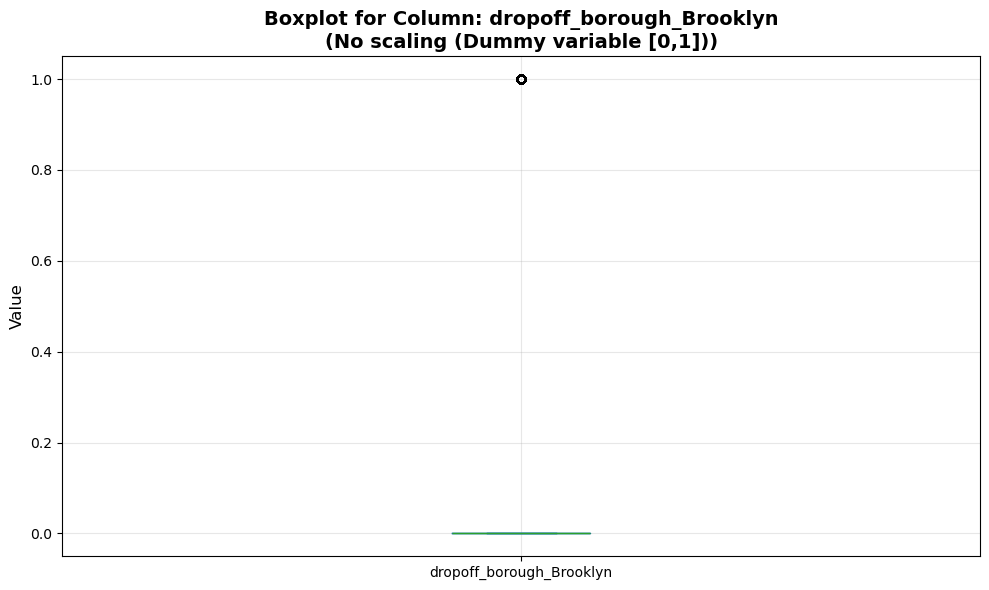

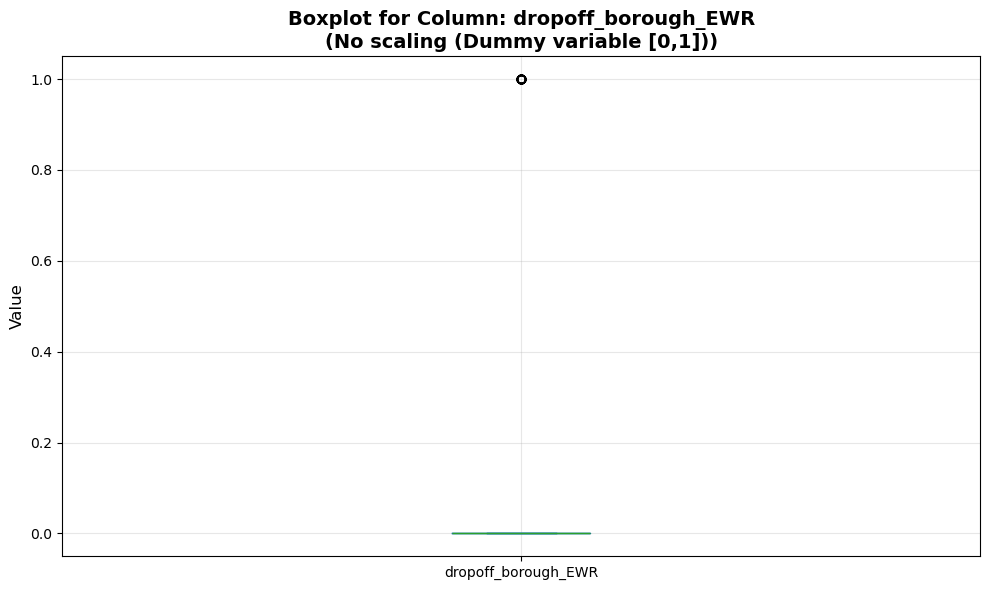

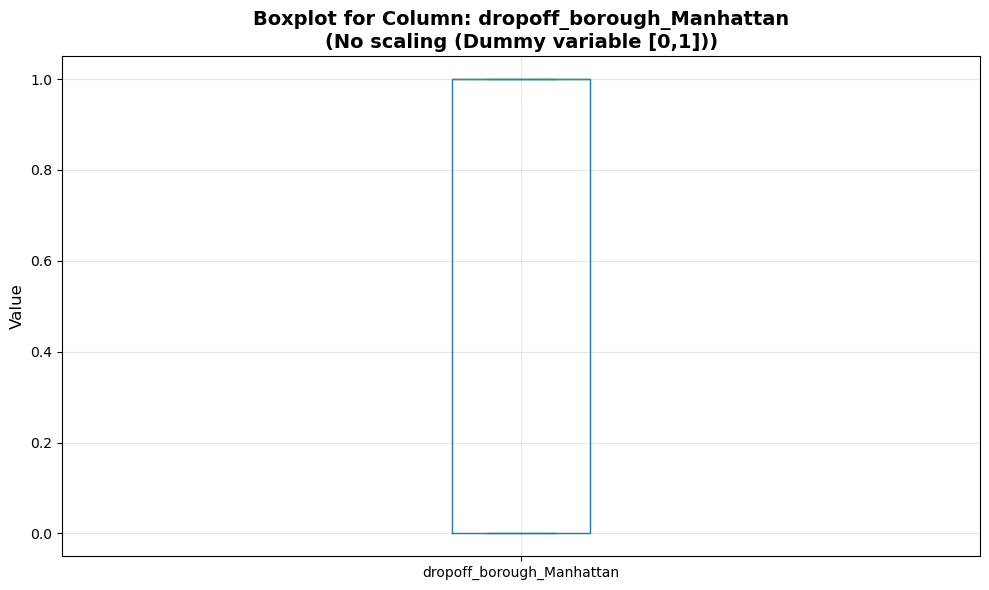

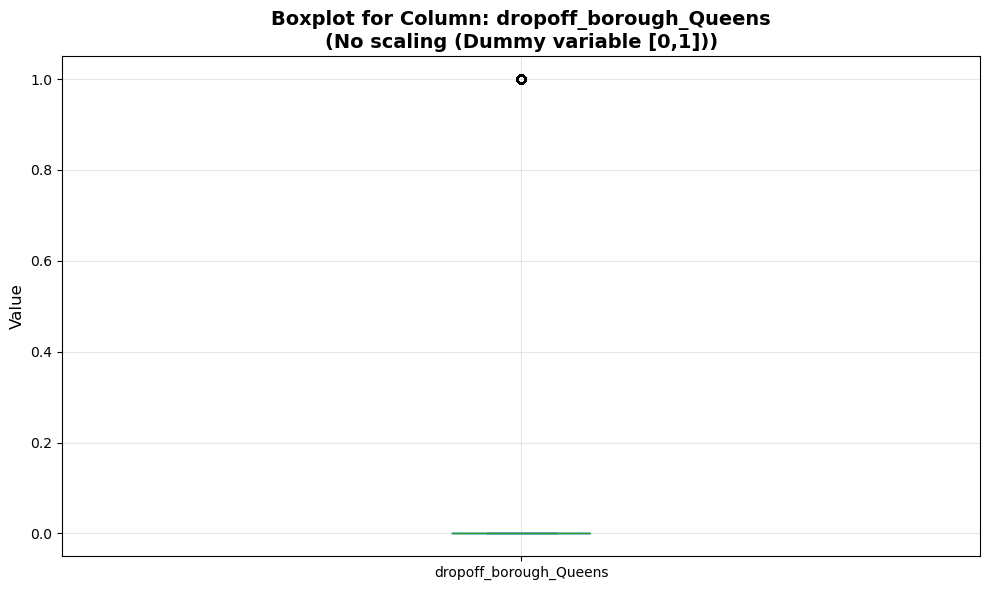

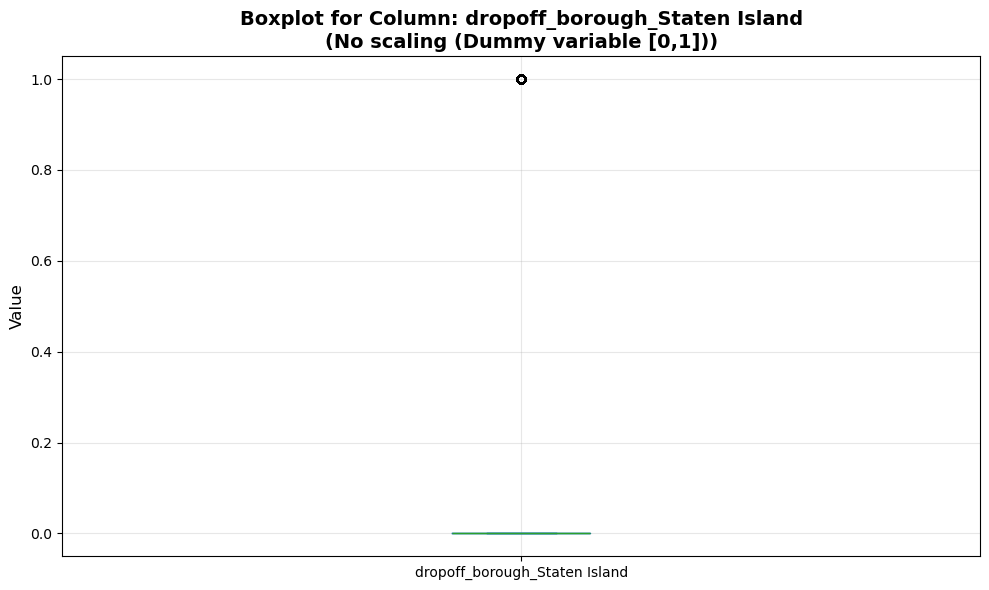

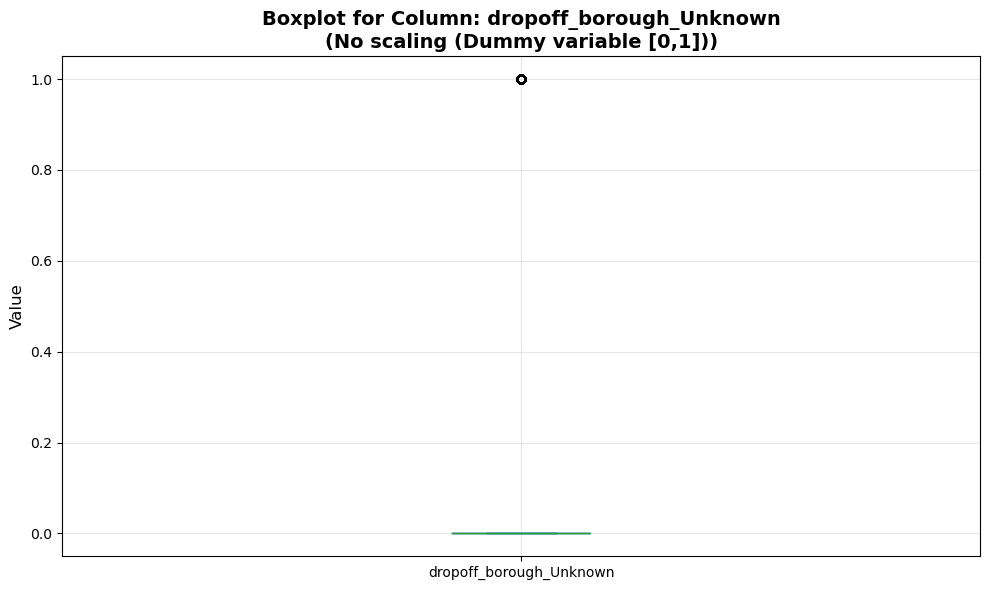

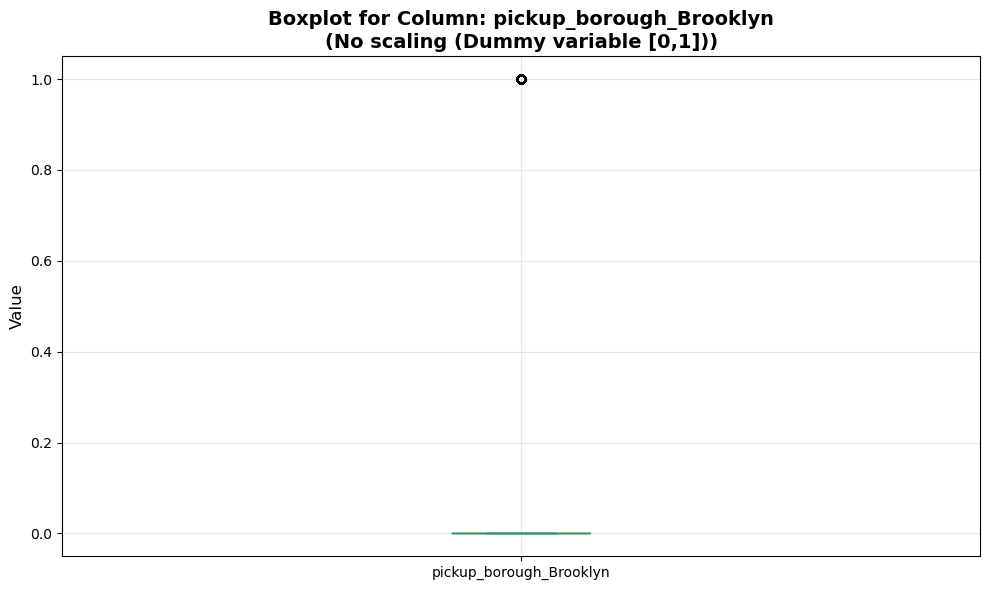

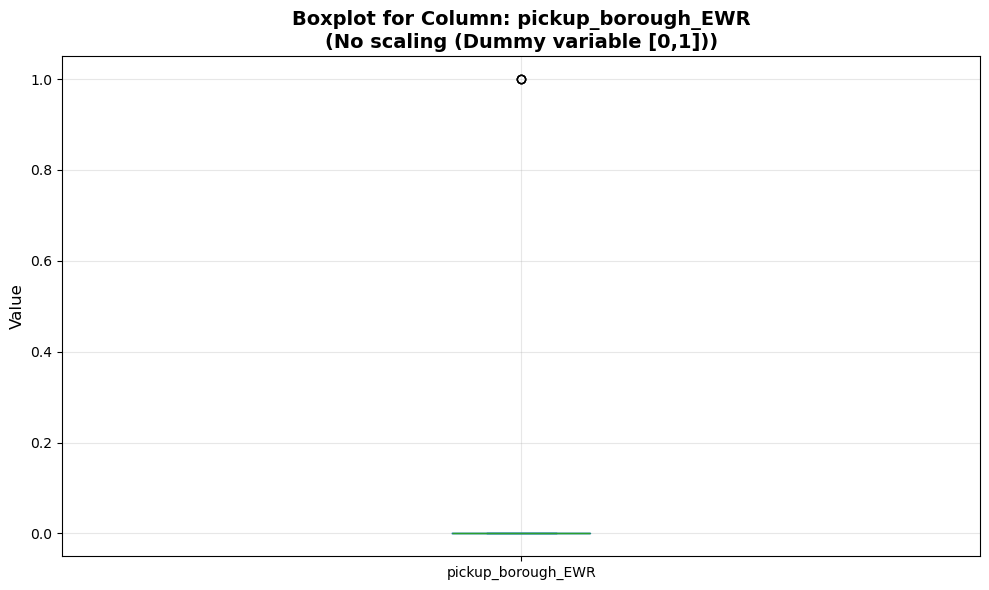

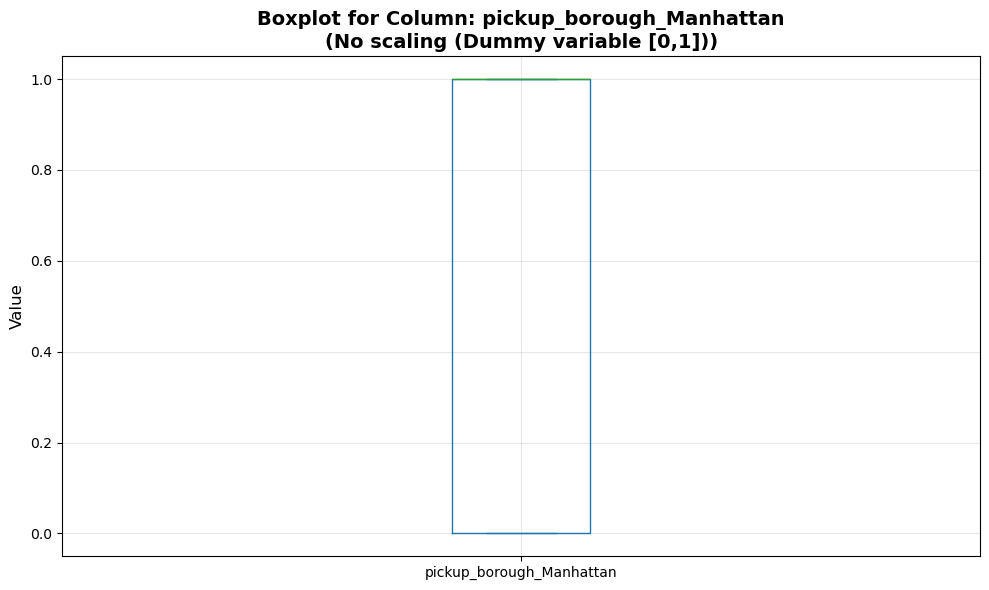

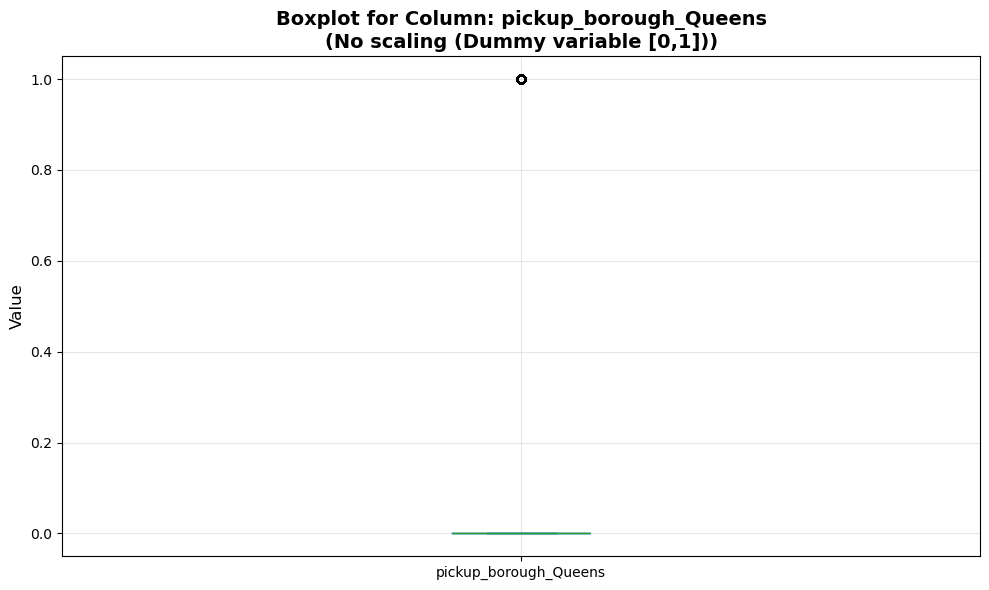

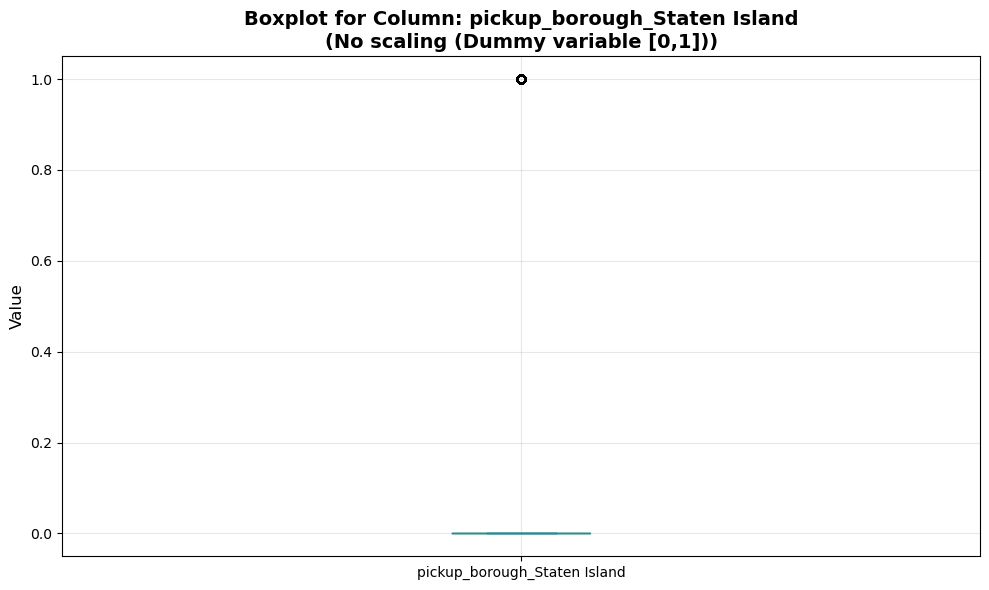

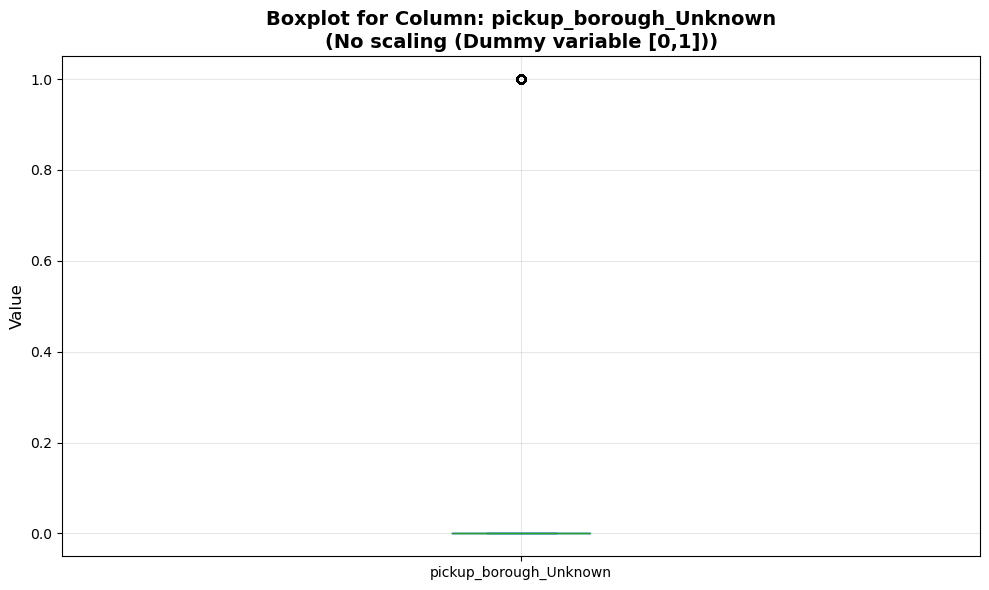

In [28]:
# Create DataFrame with original column names
aaaa = pd.DataFrame(X_train_nn, columns=nn_column_names)

# Identify dummy columns (contain underscore after categorical column names)
dummy_indicators = ['payment_type_', 'dropoff_borough_', 'pickup_borough_']
dummy_cols = [col for col in nn_column_names if any(col.startswith(prefix) for prefix in dummy_indicators)]

for col in aaaa.columns:
    fig, ax = plt.subplots(figsize=(10, 6))
    aaaa[col].plot(kind='box', ax=ax)
    
    # Determine the preprocessing applied
    if col in dummy_cols:
        preprocessing = "No scaling (Dummy variable [0,1])"
    elif col in ['mta_tax', 'extra']:
        preprocessing = "StandardScaler"
    else:
        preprocessing = "PowerTransformer"
    
    ax.set_title(f'Boxplot for Column: {col}\n({preprocessing})', fontsize=14, fontweight='bold')
    ax.set_ylabel('Value', fontsize=12)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [29]:
USE_MIXED_PRECISION = True  # Set to True to enable
USE_TF32 = True  # Enable TF32 for Ampere GPUs and newer

In [30]:
if not USE_MIXED_PRECISION:

    print("Training Neural Network (PyTorch)...")
    start_time = time.time()

    # Initialize model and move to device
    nn_model = RegressionNN(input_dim).to(device)
    
    if hasattr(torch, 'compile'):
        nn_model = torch.compile(nn_model, mode='max-autotune')
        print("Model compiled with torch.compile()")

    criterion = nn.HuberLoss(delta=1.0)
    optimizer = optim.AdamW(nn_model.parameters(), lr=0.001, weight_decay=1e-4, fused=True if device.type == 'cuda' else False)

    # Learning rate scheduler
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-6
    )

    # Training parameters
    epochs = 1000
    patience = 15
    best_loss = float('inf')
    epochs_no_improve = 0
    batch_size = 128

    # Split train into train/validation
    val_size = int(0.15 * len(X_train_tensor))
    train_size = len(X_train_tensor) - val_size
    indices = torch.randperm(len(X_train_tensor))

    # Keep data on CPU for DataLoader, move batches to GPU during training
    X_tr = X_train_tensor[indices[val_size:]]
    y_tr = y_train_tensor[indices[val_size:]]
    X_val = X_train_tensor[indices[:val_size]].to(device)
    y_val = y_train_tensor[indices[:val_size]].to(device)

    # Move test tensors to device
    X_test_tensor = X_test_tensor.to(device)
    y_test_tensor = y_test_tensor.to(device)

    # Use DataLoader for efficient batching
    train_dataset = TensorDataset(X_tr, y_tr)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True if device.type == 'cuda' else False,  num_workers=4, persistent_workers=True, prefetch_factor=2)  # Keep 0 for GPU training

    # Training loop with mini-batches
    for epoch in range(epochs):
        nn_model.train()
        train_loss = 0.0
        
        for batch_X, batch_y in train_loader:
            # Move batch to device
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            
            optimizer.zero_grad(set_to_none=True)
            outputs = nn_model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(nn_model.parameters(), max_norm=1.0)
            
            optimizer.step()
            train_loss += loss.item()
        
        train_loss /= len(train_loader)
        
        # Validation
        nn_model.eval()
        with torch.no_grad():
            val_outputs = nn_model(X_val)
            val_loss = criterion(val_outputs, y_val).item()
        
        scheduler.step(val_loss)
        
        if val_loss < best_loss:
            best_loss = val_loss
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
        
        if (epoch + 1) % 10 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, LR: {current_lr:.6f}")

    # Predict on test set
    nn_model.eval()
    with torch.no_grad():
        y_pred_nn = nn_model(X_test_tensor).squeeze().cpu().numpy()

    training_time = time.time() - start_time
    print(f"Training time: {training_time:.2f} seconds")

    results.append(evaluate_model(y_test, y_pred_nn, "Neural Network (PyTorch)"))

else:
    print("Mixed precision enabled - skipping full precision training.")

Mixed precision enabled - skipping full precision training.


Using TF32 mixed precision
Training Neural Network (PyTorch - Mixed Precision)...
Moving dataset to GPU memory...
Dataset loaded on GPU (421,512 train + 74,384 val samples)
Available GPU memory: 4,045.23 MB
Training with 2 batches of size 327,680
Moving dataset to GPU memory...
Dataset loaded on GPU (421,512 train + 74,384 val samples)
Available GPU memory: 4,045.23 MB
Training with 2 batches of size 327,680
Epoch 10/1000, Train Loss: 15.7078, Val Loss: 15.8240, LR: 0.001000
Epoch 10/1000, Train Loss: 15.7078, Val Loss: 15.8240, LR: 0.001000
Epoch 20/1000, Train Loss: 15.1453, Val Loss: 15.6785, LR: 0.001000
Epoch 20/1000, Train Loss: 15.1453, Val Loss: 15.6785, LR: 0.001000
Epoch 30/1000, Train Loss: 14.8120, Val Loss: 14.6770, LR: 0.000500
Epoch 30/1000, Train Loss: 14.8120, Val Loss: 14.6770, LR: 0.000500
Epoch 40/1000, Train Loss: 14.5472, Val Loss: 14.3820, LR: 0.000500
Epoch 40/1000, Train Loss: 14.5472, Val Loss: 14.3820, LR: 0.000500
Epoch 50/1000, Train Loss: 14.2713, Val Loss

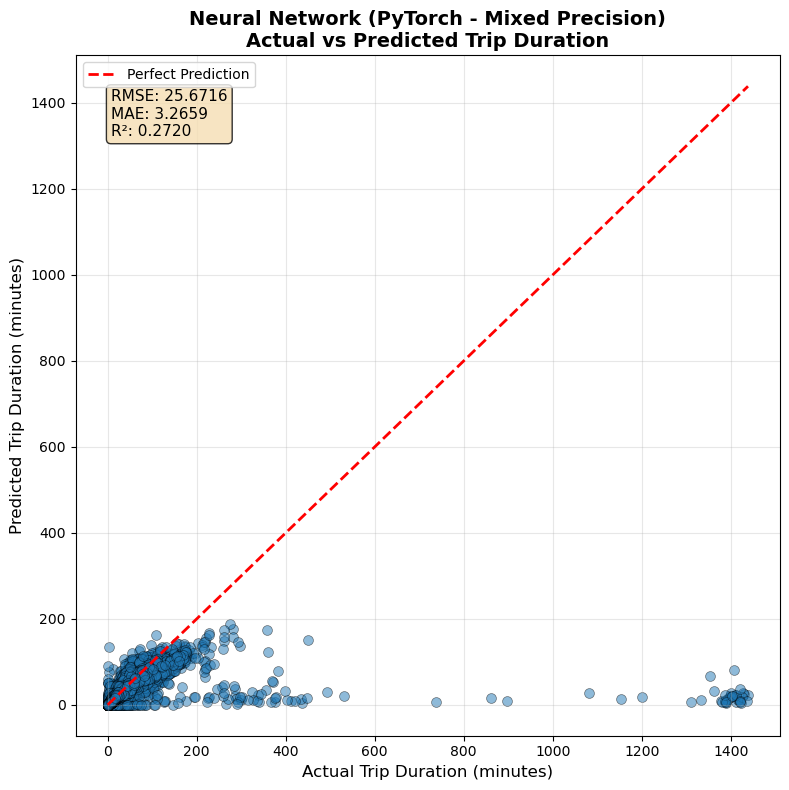

In [31]:
if USE_MIXED_PRECISION and device.type == 'cuda':
    if USE_TF32:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        print("Using TF32 mixed precision")

    else:
        print("Using FP16/FP32 mixed precision")
    
    from torch.cuda.amp import autocast, GradScaler

    scaler = GradScaler() #Scale gradient for mixed precision training

    print("Training Neural Network (PyTorch - Mixed Precision)...")
    start_time = time.time()
    
    # Initialize model (using the same RegressionNN class)
    nn_model_mp = RegressionNN(input_dim).to(device)
    criterion = nn.HuberLoss(delta=1.0)
    optimizer = optim.AdamW(nn_model_mp.parameters(), lr=0.001, weight_decay=1e-4, fused=True)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-6)
    
    epochs = 1000
    patience = 15
    best_loss = float('inf')
    epochs_no_improve = 0
    batch_size = 327680
    
    val_size = int(0.15 * len(X_train_tensor))
    indices = torch.randperm(len(X_train_tensor))

    print("Moving dataset to GPU memory...")
    X_tr = X_train_tensor[indices[val_size:]].to(device)
    y_tr = y_train_tensor[indices[val_size:]].to(device)
    X_val = X_train_tensor[indices[:val_size]].to(device)
    y_val = y_train_tensor[indices[:val_size]].to(device)
    X_test_tensor = X_test_tensor.to(device)  # Move test data to GPU
    print(f"Dataset loaded on GPU ({X_tr.shape[0]:,} train + {X_val.shape[0]:,} val samples)")
    print(f"Available GPU memory: {(torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0))/(1024**2):,.2f} MB")
    
    # Manual batching without DataLoader (removes Python overhead)
    n_samples = X_tr.shape[0]
    n_batches = (n_samples + batch_size - 1) // batch_size
    print(f"Training with {n_batches} batches of size {batch_size:,}")
    
    for epoch in range(epochs):
        nn_model_mp.train()
        train_loss = 0.0
        
        # Shuffle indices on GPU
        batch_indices = torch.randperm(n_samples, device=device)
        
        for i in range(0, n_samples, batch_size):
            # Get batch using advanced indexing (all on GPU)
            idx = batch_indices[i:min(i + batch_size, n_samples)]
            batch_X = X_tr[idx]
            batch_y = y_tr[idx]
            
            optimizer.zero_grad(set_to_none=True)
            
            # Mixed precision forward pass
            with autocast():
                outputs = nn_model_mp(batch_X)
                loss = criterion(outputs, batch_y)
            
            # Scaled backward pass
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(nn_model_mp.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            
            train_loss += loss.item()
        
        train_loss /= n_batches
        
        # Validation
        nn_model_mp.eval()
        with torch.no_grad(), autocast():
            val_outputs = nn_model_mp(X_val)
            val_loss = criterion(val_outputs, y_val).item()
        
        scheduler.step(val_loss)
        
        if val_loss < best_loss:
            best_loss = val_loss
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
        
        if (epoch + 1) % 10 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, LR: {current_lr:.6f}")
    
    # Predict on test set
    nn_model_mp.eval()
    with torch.no_grad(), autocast():
        y_pred_nn_mp = nn_model_mp(X_test_tensor).squeeze().cpu().numpy()
    
    training_time = time.time() - start_time
    print(f"Training time: {training_time:.2f} seconds")
    
    results.append(evaluate_model(y_test, y_pred_nn_mp, "Neural Network (PyTorch - Mixed Precision)"))
else:
    if device.type != 'cuda':
        print("Mixed precision training requires GPU. Currently using CPU.")
    else:
        print("Mixed precision training skipped.")


In [32]:
del X_tr , y_tr, X_val, y_val, X_test_tensor, nn_model_mp, y_pred_nn_mp
import gc
gc.collect()

15777

## 5. SVM Regressor (sklearn - CPU)

In [33]:
# clear pytorch gpu cache
torch.cuda.empty_cache()

Training SVM Regressor (sklearn - CPU)...


StandardScaler applied to: ['mta_tax', 'extra']
PowerTransformer applied to: ['fare_amount', 'tolls_amount']
SVM data shape: (495896, 20)
Dummy variables remain in [0,1] range (not transformed)
SVM data shape: (495896, 20)
Dummy variables remain in [0,1] range (not transformed)
Training time: 195.24 seconds

SVM (sklearn - CPU) - Test Set Performance
RMSE:  29.1361
MAE:   13.9430
R² Score: 0.0622
Training time: 195.24 seconds

SVM (sklearn - CPU) - Test Set Performance
RMSE:  29.1361
MAE:   13.9430
R² Score: 0.0622


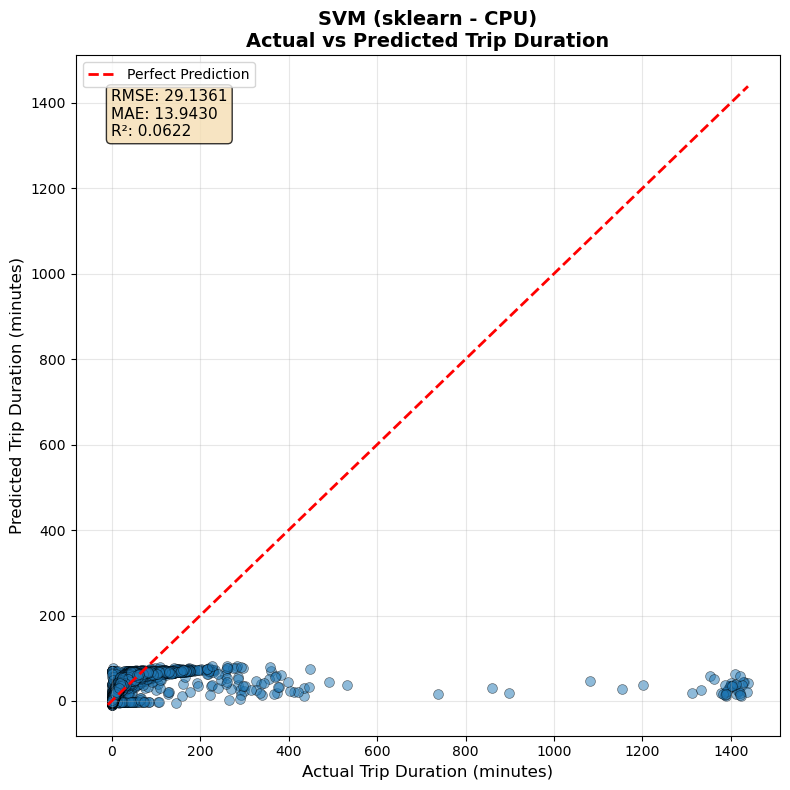

In [8]:
print("Training SVM Regressor (sklearn - CPU)...")
start_time = time.time()

# Prepare data for SVM: Same as NN - scale BEFORE dummies
X_train_svm = X_train.copy()
X_test_svm = X_test.copy()

# Identify numeric columns (before creating dummies)
numeric_cols_all = [col for col in X_train_svm.columns if col not in categorical_cols]

# Separate columns for different scaling approaches
std_scaler_cols = ['mta_tax', 'extra']
power_transform_cols = [col for col in numeric_cols_all if col not in std_scaler_cols]

# Apply StandardScaler to mta_tax and extra
scaler_std_svm = StandardScaler()
X_train_svm[std_scaler_cols] = scaler_std_svm.fit_transform(X_train_svm[std_scaler_cols])
X_test_svm[std_scaler_cols] = scaler_std_svm.transform(X_test_svm[std_scaler_cols])

# Apply PowerTransformer to other numeric columns
from sklearn.preprocessing import PowerTransformer
scaler_power_svm = PowerTransformer()
X_train_svm[power_transform_cols] = scaler_power_svm.fit_transform(X_train_svm[power_transform_cols])
X_test_svm[power_transform_cols] = scaler_power_svm.transform(X_test_svm[power_transform_cols])

print(f"StandardScaler applied to: {std_scaler_cols}")
print(f"PowerTransformer applied to: {power_transform_cols}")

# NOW convert categorical columns to dummies (after scaling numeric features)
for col in categorical_cols:
    X_train_svm[col] = X_train_svm[col].astype('category')
    X_test_svm[col] = X_test_svm[col].astype('category')

X_train_svm = pd.get_dummies(X_train_svm, columns=categorical_cols, drop_first=True)
X_test_svm = pd.get_dummies(X_test_svm, columns=categorical_cols, drop_first=True)

# Ensure both train and test have the same columns
X_train_svm, X_test_svm = X_train_svm.align(X_test_svm, join='left', axis=1, fill_value=0)

# Ensure all columns are numeric (convert any remaining object columns to float)
X_train_svm = X_train_svm.astype('float64')
X_test_svm = X_test_svm.astype('float64')

print(f"SVM data shape: {X_train_svm.shape}")
print(f"Dummy variables remain in [0,1] range (not transformed)")

# sklearn SVM with RBF kernel (CPU)
svm_model = SVR(
    kernel='rbf',
    C=10.0,
    gamma=0.01,
    epsilon=0.1,
    cache_size=1000,
    max_iter=1000
)

svm_model.fit(X_train_svm, y_train)
y_pred_svm = svm_model.predict(X_test_svm)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_svm, "SVM (sklearn - CPU)"))

In [36]:
del X_train_svm, X_test_svm, scaler_std_svm, scaler_power_svm, svm_model, y_pred_svm
import gc
gc.collect()

7680

## 6. XGBoost Regressor (CUDA-accelerated)

In [ ]:
print("Preparing data for XGBoost...")

# Prepare data for XGBoost: No scaling, convert to numpy backend with str categories
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

# Convert from pyarrow backend to numpy backend
numeric_cols = [col for col in X_train_xgb.columns if col not in categorical_cols]

# Convert numeric columns to float64 (numpy dtype)
for col in numeric_cols:
    X_train_xgb[col] = X_train_xgb[col].astype('float64')
    X_test_xgb[col] = X_test_xgb[col].astype('float64')

# Convert categorical columns from pyarrow string to python str wrapped in category
for col in categorical_cols:
    X_train_xgb[col] = X_train_xgb[col].astype(str).astype('category')
    X_test_xgb[col] = X_test_xgb[col].astype(str).astype('category')

print(f"XGBoost data shape: {X_train_xgb.shape}")
print("\nXGBoost Train dtypes:")
print(X_train_xgb.dtypes)
print("\nXGBoost Test dtypes:")
print(X_test_xgb.dtypes)


Training XGBoost Regressor...
Training time: 2.27 seconds

XGBoost - Test Set Performance
RMSE:  25.5805
MAE:   3.2943
R² Score: 0.2771
Training time: 2.27 seconds

XGBoost - Test Set Performance
RMSE:  25.5805
MAE:   3.2943
R² Score: 0.2771


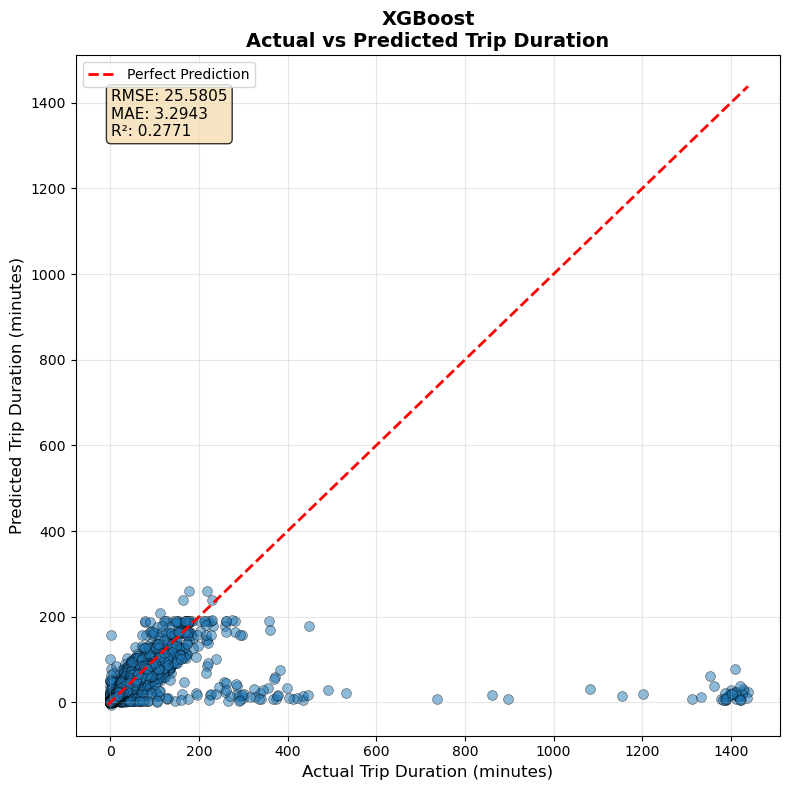

In [ ]:
print("Training XGBoost Regressor...")
start_time = time.time()

xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    tree_method='hist',  # optional when device='cuda'
    device='cuda' if device.type == 'cuda' else 'cpu',
    random_state=42,
    enable_categorical=True,
)

xgb_model.fit(
    X_train_xgb, y_train,
    eval_set=[(X_test_xgb, y_test)],
    verbose=False
)

y_pred_xgb = xgb_model.predict(X_test_xgb)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_xgb, "XGBoost"))


## 7. LightGBM Regressor (CUDA-accelerated)

Training LightGBM Regressor...
LightGBM data shape: (495896, 7)
Categorical features for LightGBM: ['payment_type', 'dropoff_borough', 'pickup_borough']
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.026274 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 309
[LightGBM] [Info] Number of data points in the train set: 495896, number of used features: 7
LightGBM data shape: (495896, 7)
Categorical features for LightGBM: ['payment_type', 'dropoff_borough', 'pickup_borough']
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.026274 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 309
[LightGBM] [Info] Number of data points in the train set: 495896, number of used features: 7
[LightGBM] [Info] Sta

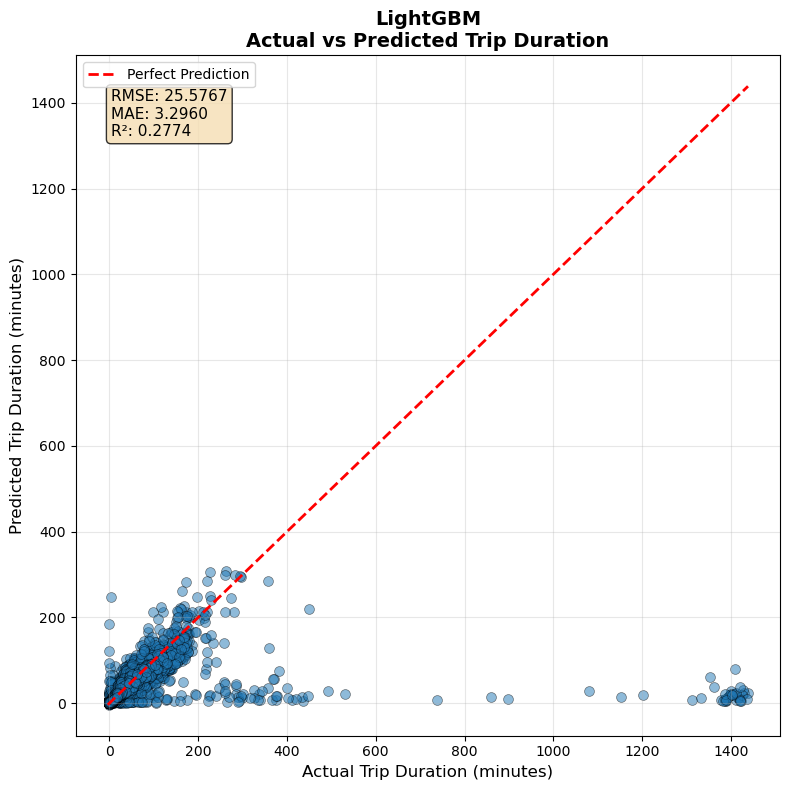

In [ ]:
print("Training LightGBM Regressor...")
start_time = time.time()

# Prepare data for LightGBM: No scaling, convert to numpy backend with str categories
X_train_lgb = X_train.copy()
X_test_lgb = X_test.copy()

# Convert from pyarrow backend to numpy backend
numeric_cols = [col for col in X_train_lgb.columns if col not in categorical_cols]

# Convert numeric columns to float64 (numpy dtype)
for col in numeric_cols:
    X_train_lgb[col] = X_train_lgb[col].astype('float64')
    X_test_lgb[col] = X_test_lgb[col].astype('float64')

# Convert categorical columns from pyarrow string to python str wrapped in category
for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].astype(str).astype('category')
    X_test_lgb[col] = X_test_lgb[col].astype(str).astype('category')

print(f"LightGBM data shape: {X_train_lgb.shape}")
print(f"Categorical features for LightGBM: {categorical_cols}")

lgb_model = lgb.LGBMRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=20,
    reg_alpha=0.1,
    reg_lambda=1.0,
    n_jobs=-1,
    random_state=42
)

lgb_model.fit(
    X_train_lgb, y_train,
    eval_set=[(X_test_lgb, y_test)],
    categorical_feature=categorical_cols,
    callbacks=[lgb.early_stopping(stopping_rounds=20), lgb.log_evaluation(period=0)]
)

y_pred_lgb = lgb_model.predict(X_test_lgb)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_lgb, "LightGBM"))


## Model Comparison
Compare all models side-by-side

In [ ]:
# Create comparison DataFrame
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('rmse')

print("\n" + "="*80)
print("MODEL COMPARISON - Sorted by RMSE (lower is better)")
print("="*80)
print(results_df.to_string(index=False))
print("="*80)

# Save results
results_df.to_csv('model_comparison_results.csv', index=False)
print("\nResults saved to model_comparison_results.csv")


MODEL COMPARISON - Sorted by RMSE (lower is better)
                                     model      rmse       mae        r2
                                  LightGBM 25.576685  3.296009  0.277366
                                   XGBoost 25.580519  3.294297  0.277149
                             Decision Tree 25.694015  3.400814  0.270721
Neural Network (PyTorch - Mixed Precision) 25.793556  3.570594  0.265059
                             Random Forest 25.829091  4.192133  0.263033
                       K-Nearest Neighbors 26.242385  3.616146  0.239259
                             SVM (sklearn) 40.052125 30.529738 -0.772071

Results saved to model_comparison_results.csv


At least two models with error distributions are required for ANOVA. Falling back to manually formatted summary metrics if available.
Using manually formatted summary metrics for ANOVA.
ANOVA Table (absolute errors):
               sum_sq   df         F    PR(>F)
C(model)    81.421657  6.0  0.059465  0.998499
Residual  1597.442998  7.0       NaN       NaN
F-statistic: 0.0595, p-value: 9.9850e-01


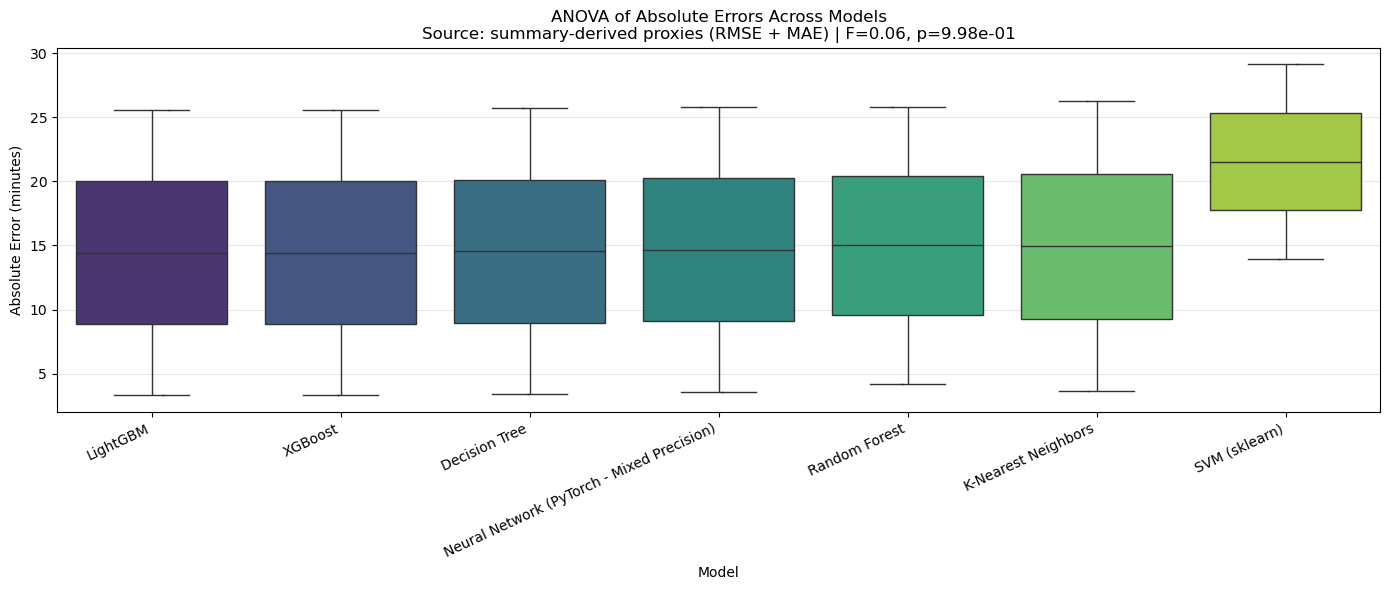

ANOVA visualization saved to model_anova_absolute_error.png


In [13]:
# Perform ANOVA to test if absolute error distributions differ across models
anova_df = None
source_label = None

model_error_data_available = 'model_error_distributions' in globals() and bool(model_error_distributions)

if model_error_data_available:
    non_empty_distributions = [errors for errors in model_error_distributions.values() if len(errors)]
    if len(non_empty_distributions) < 2:
        print("At least two models with error distributions are required for ANOVA. "
              "Falling back to manually formatted summary metrics if available.")
    else:
        anova_records = []
        for model_name, errors in model_error_distributions.items():
            if len(errors) == 0:
                continue
            valid_errors = np.asarray(errors, dtype=float)
            anova_records.extend({'model': model_name, 'abs_error': float(err)} for err in valid_errors)
        anova_df = pd.DataFrame(anova_records)
        source_label = "per-sample absolute errors"

if anova_df is None:
    if 'anova_manual_df' in globals():
        if anova_manual_df.empty:
            print("The manually formatted ANOVA dataframe is empty. Populate it before running this cell.")
        else:
            anova_df = anova_manual_df.copy()
            source_label = "summary-derived proxies (RMSE + MAE)"
            print("Using manually formatted summary metrics for ANOVA.")
    else:
        print("No stored model errors available and no manual ANOVA dataframe detected.")

if anova_df is None:
    print("Run the model training cells or execute the manual formatting cell before rerunning this block.")
elif anova_df['model'].nunique() < 2:
    print("Not enough model groups with error data for ANOVA.")
elif anova_df.groupby('model').size().min() < 2:
    print("Each model group must contain at least two observations to run ANOVA.")
else:
    anova_model = ols('abs_error ~ C(model)', data=anova_df).fit()
    anova_table = sm.stats.anova_lm(anova_model, typ=2)
    print("ANOVA Table (absolute errors):")
    print(anova_table)

    f_stat = anova_table.loc['C(model)', 'F']
    p_value = anova_table.loc['C(model)', 'PR(>F)']
    print(f"F-statistic: {f_stat:.4f}, p-value: {p_value:.4e}")

    plt.figure(figsize=(14, 6))
    sns.boxplot(data=anova_df, x='model', y='abs_error', palette='viridis')
    sns.stripplot(data=anova_df, x='model', y='abs_error', color='black', alpha=0.2, size=2)
    plt.title(f'ANOVA of Absolute Errors Across Models\nSource: {source_label} | F={f_stat:.2f}, p={p_value:.2e}')
    plt.ylabel('Absolute Error (minutes)')
    plt.xlabel('Model')
    plt.xticks(rotation=25, ha='right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('model_anova_absolute_error.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("ANOVA visualization saved to model_anova_absolute_error.png")
